# Exercises XP - Diabetes Classification

## What you will learn
- Understanding the problem
- Data collection
- Model training for classification
- Model evaluation

## What you will create
- A Logistic Regression model to predict diabetes


Completed solution for Week 5, Day 1. Run the cells in order in Colab or Jupyter with pandas, scikit-learn, NumPy, and Matplotlib. The notebook reads the official course dataset ZIP from the same folder when available and downloads it otherwise. The label records diabetes status in the dataset.


## Exercise 1 - Understanding the problem and Data Collection

We want to predict if an individual has diabetes.

- Load the diabetes dataset and explore it
- Count positive and negative cases
- Split the data into train and test


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import train_test_split

# 1. Prefer the bundled archive so a local run can work offline.
archive = Path("Diabetes prediction dataset.zip")
url = ("https://media.githubusercontent.com/media/devtlv/Datasets-GEN-AI-Bootcamp/"
       "main/Week%204/Day%202/Diabetes%20prediction%20dataset.zip")
df = pd.read_csv(archive if archive.exists() else url, compression="zip")

# 2. Inspect the schema, sample rows, missing values, and repeated records.
print(f"Rows: {len(df):,} | Columns: {df.shape[1]}")
display(df.head())
display(pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum()}))
display(df.describe(include="all").T)

Rows: 100,000 | Columns: 9


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


,dtype,missing
gender,object,0
age,float64,0
hypertension,int64,0
heart_disease,int64,0
smoking_history,object,0
bmi,float64,0
HbA1c_level,float64,0
blood_glucose_level,int64,0
diabetes,int64,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
gender,100000,3,Female,58552,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,100000.0,NaN,NaN,NaN,41.885856,22.51684,0.08,24.0,43.0,60.0,80.0
hypertension,100000.0,NaN,NaN,NaN,0.07485,0.26315,0.0,0.0,0.0,0.0,1.0
heart_disease,100000.0,NaN,NaN,NaN,0.03942,0.194593,0.0,0.0,0.0,0.0,1.0
smoking_history,100000,6,No Info,35816,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,100000.0,NaN,NaN,NaN,27.320767,6.636783,10.01,23.63,27.32,29.58,95.69
HbA1c_level,100000.0,NaN,NaN,NaN,5.527507,1.070672,3.5,4.8,5.8,6.2,9.0
blood_glucose_level,100000.0,NaN,NaN,NaN,138.05806,40.708136,80.0,100.0,140.0,159.0,300.0
diabetes,100000.0,NaN,NaN,NaN,0.085,0.278883,0.0,0.0,0.0,0.0,1.0


In [2]:
# 3. Report class counts on the original data before removing duplicates.
target = "diabetes"
counts = df[target].value_counts().reindex([0, 1], fill_value=0)
for label, name in [(0, "Negative"), (1, "Positive")]:
    print(f"{name} ({label}): {counts[label]:,} ({counts[label] / len(df):.2%})")

Negative (0): 91,500 (91.50%)
Positive (1): 8,500 (8.50%)


In [3]:
# 4. Remove exact duplicate rows before splitting so identical copies of a
# labeled record do not straddle training and test sets.
clean = df.drop_duplicates()
print(f"Exact duplicate rows removed: {len(df) - len(clean):,}")
X = clean.drop(columns=target)
y = clean[target].astype(int)

# 5. Stratification keeps the positive class proportion similar in both sets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Training: {len(y_train):,} rows ({y_train.mean():.2%} positive)")
print(f"Test: {len(y_test):,} rows ({y_test.mean():.2%} positive)")

Exact duplicate rows removed: 3,854
Training: 76,916 rows (8.82% positive)
Test: 19,230 rows (8.82% positive)



## Exercise 2 - Model picking and standardization

- Which model can we use and why
- Do we need to standardize
- If yes, apply StandardScaler


Logistic regression fits a linear equation for the log-odds of a positive result. Its coefficients are interpretable as changes in log-odds with the other features held fixed. It estimates class probabilities. Their calibration would need to be checked separately before relying on the values as risk estimates.

The numerical measurements use different scales. StandardScaler centers and rescales continuous inputs, which improves numerical conditioning and makes regularization more comparable across them. Binary indicators stay on their 0/1 scale, and text categories are one-hot encoded. The pipeline learns its preprocessing parameters from the training set.

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 1. Separate continuous measurements, 0/1 indicators, and text categories.
categorical = X_train.select_dtypes(exclude="number").columns.tolist()
numeric = X_train.select_dtypes(include="number").columns.tolist()
binary = [column for column in numeric
          if set(X_train[column].dropna().unique()).issubset({0, 1})]
continuous = [column for column in numeric if column not in binary]

# 2. Define how each group is transformed. Imputation handles missing entries
# using the training median or the most frequent training category.
numeric_steps = Pipeline([
    ("fill", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
categorical_steps = Pipeline([
    ("fill", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore")),
])
preprocess = ColumnTransformer([
    ("continuous", numeric_steps, continuous),
    ("binary", SimpleImputer(strategy="most_frequent"), binary),
    ("categorical", categorical_steps, categorical),
])

## Exercise 3 - Model training

In [5]:
from sklearn.linear_model import LogisticRegression

# One fit learns both the preprocessing parameters and model coefficients
# from the training rows. Prediction automatically applies the same transforms.
model = Pipeline([
    ("preprocess", preprocess),
    ("logistic", LogisticRegression(max_iter=1000, random_state=42)),
])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, list(model.classes_).index(1)]


## Exercise 4 - Evaluation metrics

- Plot accuracy and comment
- Plot confusion matrix and comment
- Plot precision, recall, F1 and comment


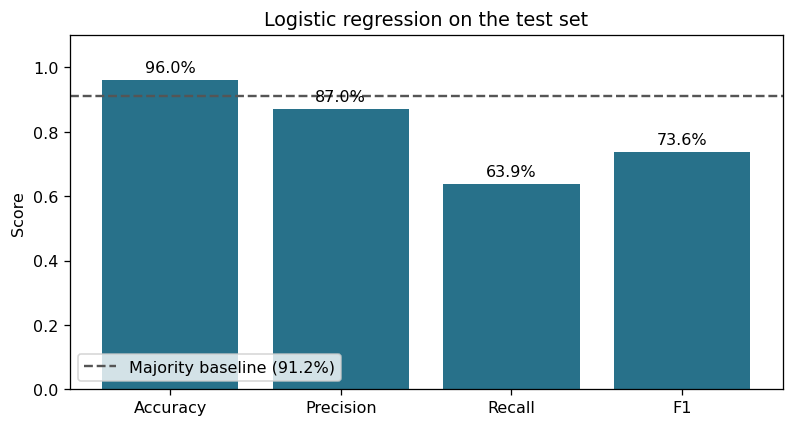

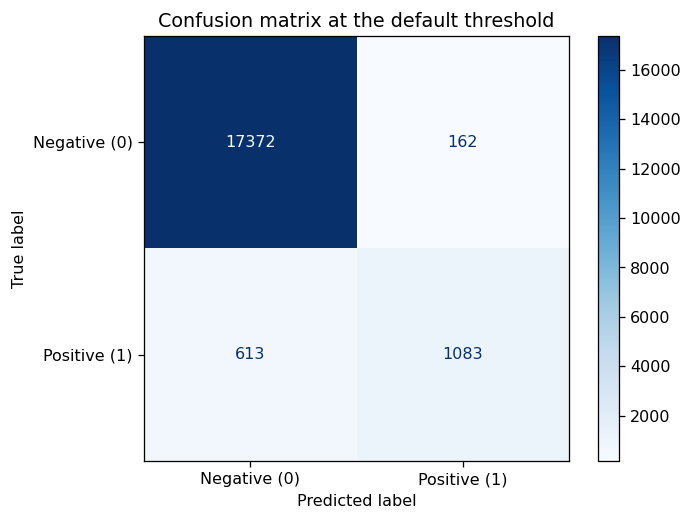

Accuracy: 96.0% vs. 91.2% for always predicting the majority class.
Correctly identified 17,372 negatives and 1,083 positives.
False alarms: 162. Missed positives: 613.
Precision: 87.0% of predicted positives were positive.
Recall: 63.9% of actual positives were detected.
F1: 73.6%, the harmonic mean of precision and recall.
Lowering the threshold can catch more positives while increasing false alarms.


In [6]:
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, confusion_matrix,
    f1_score, precision_score, recall_score,
)

# 1. Score the predicted labels at the default 0.50 probability threshold.
scores = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1": f1_score(y_test, y_pred, zero_division=0),
}
baseline = y_test.value_counts(normalize=True).max()

# 2. Plot each score and show the always-negative accuracy baseline.
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(scores.keys(), scores.values(), color="#28718a")
ax.bar_label(bars, labels=[f"{value:.1%}" for value in scores.values()], padding=3)
ax.axhline(baseline, color="#555555", ls="--", label=f"Majority baseline ({baseline:.1%})")
ax.set(ylim=(0, 1.1), ylabel="Score", title="Logistic regression on the test set")
ax.legend(loc="lower left")
plt.show()

# 3. Rows are actual labels and columns are predictions. The fixed label
# order means ravel() returns TN, FP, FN, TP in that order.
matrix = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = matrix.ravel()
ConfusionMatrixDisplay(matrix, display_labels=["Negative (0)", "Positive (1)"]).plot(
    cmap="Blues", values_format="d"
)
plt.title("Confusion matrix at the default threshold")
plt.show()

# 4. Read the metrics together because most records are negative.
print(f"Accuracy: {scores['Accuracy']:.1%} vs. {baseline:.1%} for always predicting the majority class.")
print(f"Correctly identified {tn:,} negatives and {tp:,} positives.")
print(f"False alarms: {fp:,}. Missed positives: {fn:,}.")
print(f"Precision: {scores['Precision']:.1%} of predicted positives were positive.")
print(f"Recall: {scores['Recall']:.1%} of actual positives were detected.")
print(f"F1: {scores['F1']:.1%}, the harmonic mean of precision and recall.")
print("Lowering the threshold can catch more positives while increasing false alarms.")

Test accuracy was 95.97%, compared with 91.18% for always predicting the majority class. Precision was 86.99%, while recall was 63.86%. The model's positive predictions were usually correct, but it missed 613 actual positives. The F1 score was 73.65%.

## Exercise 5 - Visualizing the performance of our model

Visualize a 2D decision boundary with accuracy info. Use only two informative features for this plot to keep it 2D. Suggested pair: `HbA1c_level` and `blood_glucose_level` if present. Otherwise pick any two numeric features.


Light areas show the two-feature model's predictions. The dots show actual test labels.

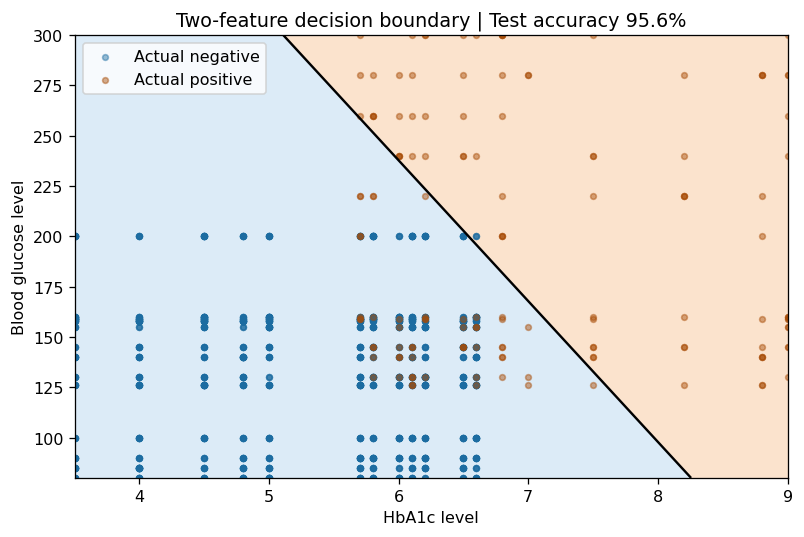

Two-feature accuracy: 95.56% | Full model: 95.97%


In [7]:
# 1. Reuse the same train/test rows and train a model with only two measurements.
features = ["HbA1c_level", "blood_glucose_level"]
two_train, two_test = X_train[features], X_test[features]
two_model = Pipeline([
    ("fill", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("logistic", LogisticRegression(max_iter=1000, random_state=42)),
])
two_model.fit(two_train, y_train)
two_accuracy = two_model.score(two_test, y_test)

# 2. Evaluate predicted positive probabilities across a grid in original units.
ranges = [np.linspace(two_train[col].min(), two_train[col].max(), 200)
          for col in features]
xx, yy = np.meshgrid(*ranges)
grid = pd.DataFrame({features[0]: xx.ravel(), features[1]: yy.ravel()})
probabilities = two_model.predict_proba(grid)[:, 1].reshape(xx.shape)

# 3. Draw the 0.50 boundary and overlay a reproducible sample to reduce clutter.
fig, ax = plt.subplots(figsize=(8, 5))
ax.contourf(xx, yy, probabilities, levels=[0, 0.5, 1], colors=["#dcebf7", "#fbe3cd"])
ax.contour(xx, yy, probabilities, levels=[0.5], colors="black", linewidths=1.5)
sample = two_test.sample(n=min(1500, len(two_test)), random_state=42)
for label, name, color in [(0, "Actual negative", "#1c6ca1"), (1, "Actual positive", "#a74b05")]:
    points = sample.loc[y_test.loc[sample.index].eq(label)]
    ax.scatter(points[features[0]], points[features[1]], label=name,
               color=color, s=13, alpha=0.45)
ax.set(xlabel="HbA1c level", ylabel="Blood glucose level",
       title=f"Two-feature decision boundary | Test accuracy {two_accuracy:.1%}")
ax.legend()
plt.show()
print(f"Two-feature accuracy: {two_accuracy:.2%} | Full model: {scores['Accuracy']:.2%}")

## Exercise 6 - ROC curve

Use the code template provided to plot the ROC curve for your model and compute AUC. You can reuse the fitted `model` pipeline.

Template summary:
- Get predicted probabilities for the positive class
- Compute fpr and tpr with `roc_curve`
- Plot ROC and print AUC

[ROC template linked by the course](https://www.statology.org/plot-roc-curve-python/)

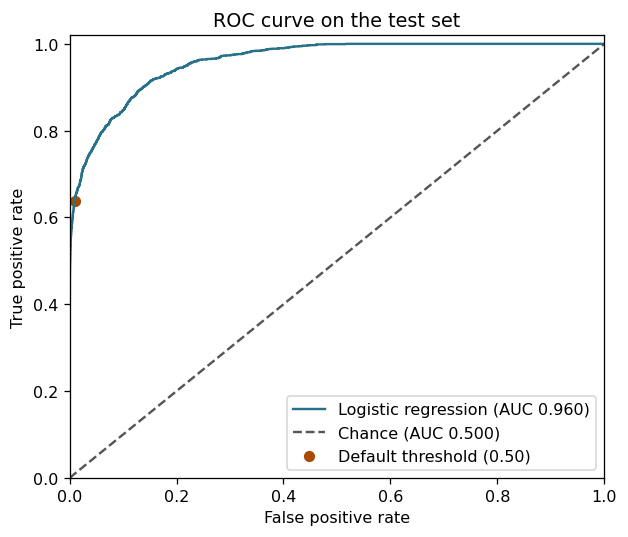

ROC AUC: 0.960. A randomly drawn positive receives a higher score than a randomly drawn negative about 96.0% of the time, counting ties as half.
At the default threshold, the model detects 63.9% of test positives.


In [8]:
from sklearn.metrics import roc_auc_score, roc_curve

# 1. Use probabilities so the ROC curve can evaluate many thresholds.
fpr, tpr, _ = roc_curve(y_test, y_proba, pos_label=1)
auc = roc_auc_score(y_test, y_proba)

# 2. Add both the chance baseline and the default-threshold operating point.
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, color="#28718a", label=f"Logistic regression (AUC {auc:.3f})")
ax.plot([0, 1], [0, 1], "--", color="#555555", label="Chance (AUC 0.500)")
ax.scatter(fp / (fp + tn), tp / (tp + fn), color="#a74b05", label="Default threshold (0.50)")
ax.set(xlim=(0, 1), ylim=(0, 1.02), xlabel="False positive rate",
       ylabel="True positive rate", title="ROC curve on the test set")
ax.legend(loc="lower right")
plt.show()

# 3. Explain AUC as a ranking statistic and connect it to threshold-specific recall.
print(f"ROC AUC: {auc:.3f}. A randomly drawn positive receives a higher score "
      f"than a randomly drawn negative about {auc:.1%} of the time, counting ties as half.")
print(f"At the default threshold, the model detects {scores['Recall']:.1%} of test positives.")

The test ROC AUC was 0.960, indicating strong ranking on this split. The default threshold still detected only 63.86% of actual positives. Ranking performance and recall at a chosen threshold answer different questions.